# 02 — AO PSF, seeing, diffraction and spaxel encircled energy

**Portfolio / learning project — not a calibrated instrument simulator.** All quantities below are synthetic proxies, literature-derived presets, or engineering estimates (see the [provenance table](../docs/model_details.md#data-provenance)).

This notebook is narrative and self-contained; run the cells top to bottom.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
FIG = pathlib.Path.cwd().parent / 'figures' / 'notebooks'
FIG.mkdir(parents=True, exist_ok=True)


## Three PSF proxies
We compare a diffraction-limited **Airy** core, a **seeing** Gaussian, and a Strehl-weighted **AO** core+halo. These are synthetic proxies that capture the key trend for an AO-fed IFU: better AO concentrates light into fewer spaxels.

In [2]:
from ao_fed_ifu import psf_coupling as psf
lam, D, seeing = 2.2, 8.0, 600.0
fine = 4.0   # mas/pixel fine grid
airy   = psf.airy_psf_proxy(lam, D, grid_mas=fine, n_pix=161)
see    = psf.seeing_gaussian_psf(seeing, grid_mas=fine, n_pix=161)
ao_lo  = psf.ao_corrected_psf_proxy(0.1, lam, D, seeing, grid_mas=fine, n_pix=161)
ao_hi  = psf.ao_corrected_psf_proxy(0.6, lam, D, seeing, grid_mas=fine, n_pix=161)
print('diffraction FWHM [mas]:', round(psf.diffraction_fwhm_mas(lam, D), 1))

diffraction FWHM [mas]: 58.1


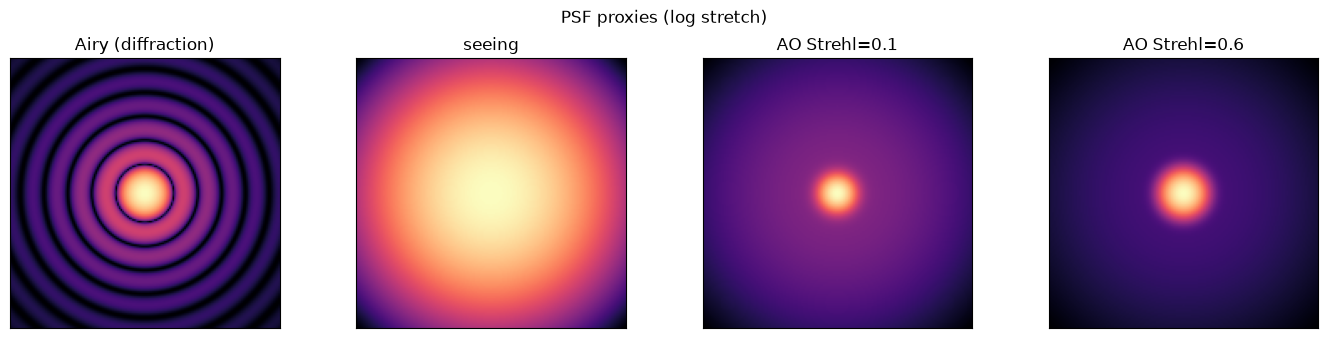

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
for a, p, t in zip(ax, [airy, see, ao_lo, ao_hi],
        ['Airy (diffraction)', 'seeing', 'AO Strehl=0.1', 'AO Strehl=0.6']):
    a.imshow(np.log10(p + p.max()*1e-4), origin='lower', cmap='magma'); a.set_title(t)
    a.set_xticks([]); a.set_yticks([])
fig.suptitle('PSF proxies (log stretch)'); fig.tight_layout()
fig.savefig(FIG / 'nb02_psfs.png', dpi=110); plt.show()

## Encircled energy vs Strehl and spaxel scale
`encircled_energy_per_spaxel` bins the fine PSF onto a spaxel grid and reports EE1 (central spaxel) and EE3x3. Higher Strehl raises both — the AO coupling gain.

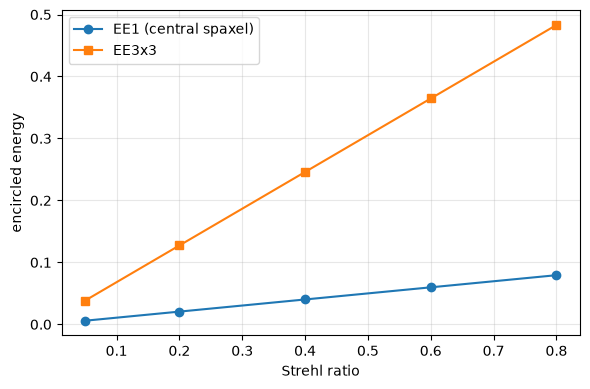

,strehl,EE1,EE3x3,fwhm_mas
0,0.05,0.005878,0.038428,66.627352
1,0.20,0.020571,0.127356,60.476250
2,0.40,0.040161,0.245928,59.502847
3,0.60,0.059752,0.364500,59.178191
4,0.80,0.079343,0.483071,59.015827


In [4]:
rows = []
for strehl in [0.05, 0.2, 0.4, 0.6, 0.8]:
    p = psf.ao_corrected_psf_proxy(strehl, lam, D, seeing, grid_mas=fine, n_pix=161)
    ee1, ee3, _ = psf.encircled_energy_per_spaxel(p, fine, spaxel_scale_mas=20.0)
    m = psf.psf_metrics(p, fine, 20.0)
    rows.append({'strehl': strehl, 'EE1': ee1, 'EE3x3': ee3, 'fwhm_mas': m.fwhm_mas})
df = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(df.strehl, df.EE1, 'o-', label='EE1 (central spaxel)')
ax.plot(df.strehl, df.EE3x3, 's-', label='EE3x3')
ax.set_xlabel('Strehl ratio'); ax.set_ylabel('encircled energy'); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIG / 'nb02_encircled_energy.png', dpi=110); plt.show()
df.to_csv(FIG / 'nb02_summary.csv', index=False); df